# 5 · Nonlinear simulation

Doublets on the nonlinear 747, the linear prediction, and the modes read back from the time
history. Lesson: [05](../docs/lessons/05-nonlinear-simulation.md) ·
Theory: [nonlinear simulation](../docs/nonlinear_simulation.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from flightdyn import plotting as P

P.use_style()
np.set_printoptions(precision=4, suppress=True)
sys.path.insert(0, "../validation")  # cited reference data and reference aircraft
from reference_aircraft import b747, b747_condition, navion, navion_condition
from flightdyn.linearization import linearize
from flightdyn.nonlinear_sim import Doublet, damped_pairs, matrix_pencil, simulate, simulate_linear
from flightdyn.trim_solver import trim

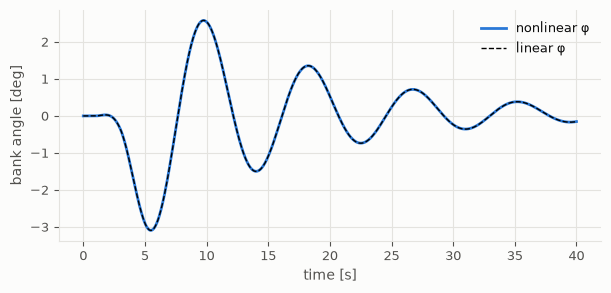

In [2]:
ac, c = b747(2), b747_condition(2)
t = trim(ac, c["V"], c["h"])
lm = linearize(ac, t)
LAT = [1, 3, 5, 6]
doublet = [Doublet("dr", np.radians(3.0), 1.0, 2.0)]
nl = simulate(ac, t.x, t.controls, doublet, t_end=40.0, dt=0.05)
lin = simulate_linear(lm.submodel(LAT, [1, 2]), doublet, t_end=40.0, dt=0.05,
                      control_index=(1, 2))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(nl.t, np.degrees(nl.x[:, 6] - t.x[6]), label="nonlinear φ")
ax.plot(lin.t, np.degrees(lin.x[:, 3]), "--", color="k", lw=1, label="linear φ")
ax.set_xlabel("time [s]")
ax.set_ylabel("bank angle [deg]")
ax.legend();

## Modes of the nonlinear response (matrix pencil)

A small doublet keeps the response linear, so the identified poles should be the linear
eigenvalues; at 3° the roll root already moves by a few percent (Lesson 5, section 4).

In [3]:
small = simulate(ac, t.x, t.controls, [Doublet("dr", np.radians(0.25), 1.0, 2.0)],
                 t_end=60.0, dt=0.05)
free = small.t >= 5.0
found = matrix_pencil(small.x[free][:, LAT] - t.x[LAT], 0.05, 4)
eig = np.linalg.eigvals(lm.A[np.ix_(LAT, LAT)])
print("identified:", np.round(np.sort_complex(found), 4))
print("linear:    ", np.round(np.sort_complex(eig), 4))

identified: [-1.2251+0.j     -0.079 -0.7404j -0.079 +0.7404j -0.0467+0.j    ]
linear:     [-1.2253+0.j     -0.079 -0.7404j -0.079 +0.7404j -0.0467+0.j    ]
